In [1]:
import os, json, joblib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, balanced_accuracy_score,
                             recall_score, precision_score, confusion_matrix, classification_report,
                             roc_curve, precision_recall_curve, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

DATA_PATH = r"C:\Users\minsa_\Downloads\Final_Features.csv"
OUT_DIR = os.path.dirname(DATA_PATH)
RANDOM_STATE = 42
FEATURES = ["ECD_CD_cells_per_mm2", "ECD_Deficit", "SD", "CV", "HEX_percent", "Donor_Age"]

df = pd.read_csv(DATA_PATH)
df["Target_Severity"] = df["Target_Severity"].fillna("None")
df["Disease_Present"] = (df["Target_Class"] != "Normal").astype(int)   # 1 = diseased, 0 = normal

train = df[df["Split"] == "train"].reset_index(drop=True)
test  = df[df["Split"] == "test"].reset_index(drop=True)
X_train, y_train, g_train = train[FEATURES], train["Disease_Present"], train["Donor_Group"]
X_test,  y_test           = test[FEATURES],  test["Disease_Present"]

print("Train:", X_train.shape, "| Test:", X_test.shape)
display(pd.crosstab(df["Disease_Present"].map({0: "Normal", 1: "Diseased"}), df["Split"]))
display(pd.crosstab(df["Target_Class"], df["Split"]))

Train: (838, 6) | Test: (210, 6)


Split,test,train
Disease_Present,,
Diseased,109,435
Normal,101,403


Split,test,train
Target_Class,,
FECD/Endothelial,27,109
Folds,65,259
Guttata,17,67
Normal,101,403


In [2]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def make_pipe(model, scale=True):
    steps = [("imp", SimpleImputer(strategy="median"))]
    if scale:
        steps.append(("sc", StandardScaler()))
    steps.append(("model", model))
    return Pipeline(steps)

candidates = {
    "Baseline (majority)": (make_pipe(DummyClassifier(strategy="most_frequent")), {}),
    "Logistic Regression": (
        make_pipe(LogisticRegression(class_weight="balanced", max_iter=5000, random_state=RANDOM_STATE)),
        {"model__C": [0.01, 0.1, 1, 10]}),
    "SVM (RBF)": (
        make_pipe(SVC(class_weight="balanced", probability=True, random_state=RANDOM_STATE)),
        {"model__C": [0.1, 1, 10], "model__gamma": ["scale", 0.1]}),
    "Random Forest": (
        make_pipe(RandomForestClassifier(class_weight="balanced_subsample", n_estimators=300,
                                         random_state=RANDOM_STATE, n_jobs=-1), scale=False),
        {"model__max_depth": [3, 5, None], "model__min_samples_leaf": [1, 5, 10]}),
    "Gradient Boosting": (
        make_pipe(HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE), scale=False),
        {"model__learning_rate": [0.03, 0.1], "model__max_depth": [2, 3, None],
         "model__min_samples_leaf": [10, 30]}),
}

In [3]:
results, best_models, oof_proba = [], {}, {}
for name, (pipe, grid) in candidates.items():
    if grid:
        gs = GridSearchCV(pipe, grid, scoring="roc_auc", cv=cv, n_jobs=-1)
        gs.fit(X_train, y_train, groups=g_train)
        best, params = gs.best_estimator_, gs.best_params_
    else:
        best, params = pipe.fit(X_train, y_train), {}
    proba = cross_val_predict(best, X_train, y_train, cv=cv, groups=g_train, method="predict_proba")[:, 1]
    pred = (proba >= 0.5).astype(int)
    best_models[name], oof_proba[name] = best, proba
    results.append({
        "Model": name,
        "ROC_AUC": roc_auc_score(y_train, proba),
        "PR_AUC": average_precision_score(y_train, proba),
        "Balanced_Acc": balanced_accuracy_score(y_train, pred),
        "Sensitivity": recall_score(y_train, pred),
        "Specificity": recall_score(y_train, pred, pos_label=0),
        "F1_Diseased": f1_score(y_train, pred),
        "Best_params": params,
    })

cv_results = pd.DataFrame(results).set_index("Model")
print("Donor-grouped 5-fold CV on TRAIN (threshold 0.5)")
cv_results.round(3)

Donor-grouped 5-fold CV on TRAIN (threshold 0.5)


,ROC_AUC,PR_AUC,Balanced_Acc,Sensitivity,Specificity,F1_Diseased,Best_params
Model,,,,,,,
Baseline (majority),0.500,0.519,0.500,1.000,0.000,0.683,{}
Logistic Regression,0.673,0.689,0.619,0.540,0.697,0.593,{'model__C': 10}
SVM (RBF),0.667,0.681,0.611,0.572,0.650,0.604,"{'model__C': 1, 'model__gamma': 0.1}"
Random Forest,0.677,0.692,0.608,0.492,0.725,0.563,"{'model__max_depth': 5, 'model__min_samples_le..."
Gradient Boosting,0.679,0.699,0.613,0.552,0.675,0.596,"{'model__learning_rate': 0.03, 'model__max_dep..."


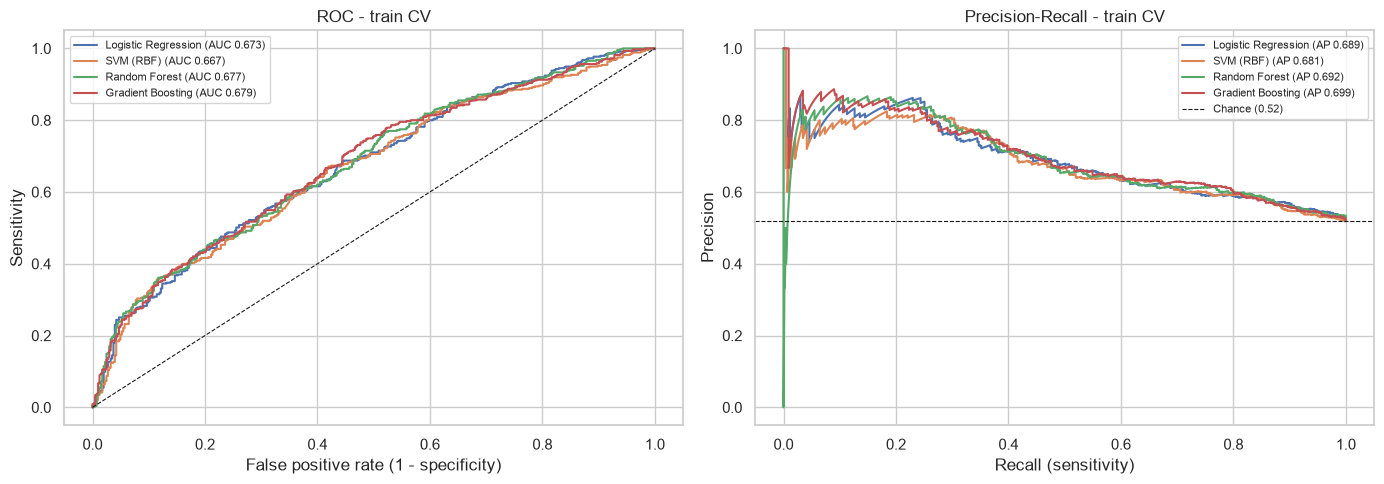

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, proba in oof_proba.items():
    if name.startswith("Baseline"): continue
    fpr, tpr, _ = roc_curve(y_train, proba)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_train, proba):.3f})")
    prec, rec, _ = precision_recall_curve(y_train, proba)
    axes[1].plot(rec, prec, label=f"{name} (AP {average_precision_score(y_train, proba):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[0].set(xlabel="False positive rate (1 - specificity)", ylabel="Sensitivity", title="ROC - train CV")
axes[1].axhline(y_train.mean(), color="k", ls="--", lw=0.8, label=f"Chance ({y_train.mean():.2f})")
axes[1].set(xlabel="Recall (sensitivity)", ylabel="Precision", title="Precision-Recall - train CV")
for ax in axes: ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

Selected model: Gradient Boosting | params: {'model__learning_rate': 0.03, 'model__max_depth': 3, 'model__min_samples_leaf': 30}
Threshold chosen on train CV (max balanced accuracy): 0.44


,Threshold,Sensitivity,Specificity,Balanced_Acc,F1_Diseased
5,0.30,0.949,0.144,0.547,0.692
10,0.40,0.811,0.404,0.608,0.687
12,0.44,0.749,0.501,0.625,0.678
15,0.50,0.552,0.675,0.613,0.596
20,0.60,0.349,0.878,0.614,0.478


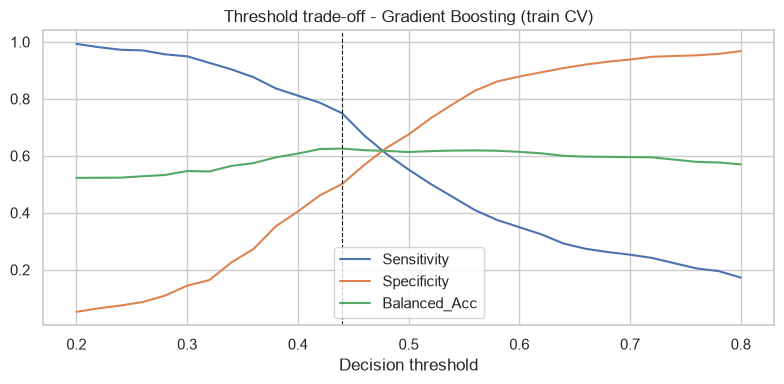

In [5]:
BEST_NAME = cv_results.drop(index="Baseline (majority)")["ROC_AUC"].idxmax()
best_model = best_models[BEST_NAME]
best_oof = oof_proba[BEST_NAME]
print("Selected model:", BEST_NAME, "| params:", cv_results.loc[BEST_NAME, "Best_params"])

thr_grid = np.round(np.arange(0.20, 0.81, 0.02), 2)
rows = []
for t in thr_grid:
    p = (best_oof >= t).astype(int)
    rows.append({"Threshold": t, "Sensitivity": recall_score(y_train, p),
                 "Specificity": recall_score(y_train, p, pos_label=0),
                 "Balanced_Acc": balanced_accuracy_score(y_train, p), "F1_Diseased": f1_score(y_train, p)})
thr_table = pd.DataFrame(rows)
THRESHOLD = float(thr_table.loc[thr_table["Balanced_Acc"].idxmax(), "Threshold"])
print(f"Threshold chosen on train CV (max balanced accuracy): {THRESHOLD}")
display(thr_table[thr_table["Threshold"].isin([0.3, 0.4, 0.5, 0.6, THRESHOLD])].round(3))

plt.figure(figsize=(8, 4))
for c in ["Sensitivity", "Specificity", "Balanced_Acc"]:
    plt.plot(thr_table["Threshold"], thr_table[c], label=c)
plt.axvline(THRESHOLD, color="k", ls="--", lw=0.8)
plt.xlabel("Decision threshold"); plt.title(f"Threshold trade-off - {BEST_NAME} (train CV)")
plt.legend(); plt.tight_layout(); plt.show()

In [6]:
oof_pred = (best_oof >= THRESHOLD).astype(int)
det = train.assign(Pred=oof_pred).groupby("Target_Class")["Pred"].mean().round(3)
print("Share predicted 'Diseased' per true class (train CV):")
det.to_frame("Predicted_Diseased_rate")

Share predicted 'Diseased' per true class (train CV):


,Predicted_Diseased_rate
Target_Class,
FECD/Endothelial,0.972
Folds,0.676
Guttata,0.672
Normal,0.499


In [7]:
final_model = best_model.fit(X_train, y_train)
test_proba = final_model.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= THRESHOLD).astype(int)

test_metrics = {
    "ROC_AUC": roc_auc_score(y_test, test_proba),
    "PR_AUC": average_precision_score(y_test, test_proba),
    "Balanced_Acc": balanced_accuracy_score(y_test, test_pred),
    "Sensitivity": recall_score(y_test, test_pred),
    "Specificity": recall_score(y_test, test_pred, pos_label=0),
    "Precision_Diseased": precision_score(y_test, test_pred),
    "F1_Diseased": f1_score(y_test, test_pred),
}
print(f"HELD-OUT TEST - {BEST_NAME}, threshold {THRESHOLD}")
display(pd.Series(test_metrics).round(3).to_frame("Test"))
print(classification_report(y_test, test_pred, target_names=["Normal", "Diseased"], zero_division=0))

rng = np.random.default_rng(RANDOM_STATE)
boot = []
for _ in range(1000):
    i = rng.integers(0, len(y_test), len(y_test))
    if y_test.iloc[i].nunique() == 2:
        boot.append(roc_auc_score(y_test.iloc[i], test_proba[i]))
print(f"Test ROC-AUC 95% bootstrap CI: [{np.percentile(boot, 2.5):.3f}, {np.percentile(boot, 97.5):.3f}]")

HELD-OUT TEST - Gradient Boosting, threshold 0.44


,Test
ROC_AUC,0.670
PR_AUC,0.699
Balanced_Acc,0.606
Sensitivity,0.697
Specificity,0.515
Precision_Diseased,0.608
F1_Diseased,0.650


              precision    recall  f1-score   support

      Normal       0.61      0.51      0.56       101
    Diseased       0.61      0.70      0.65       109

    accuracy                           0.61       210
   macro avg       0.61      0.61      0.60       210
weighted avg       0.61      0.61      0.61       210

Test ROC-AUC 95% bootstrap CI: [0.602, 0.740]


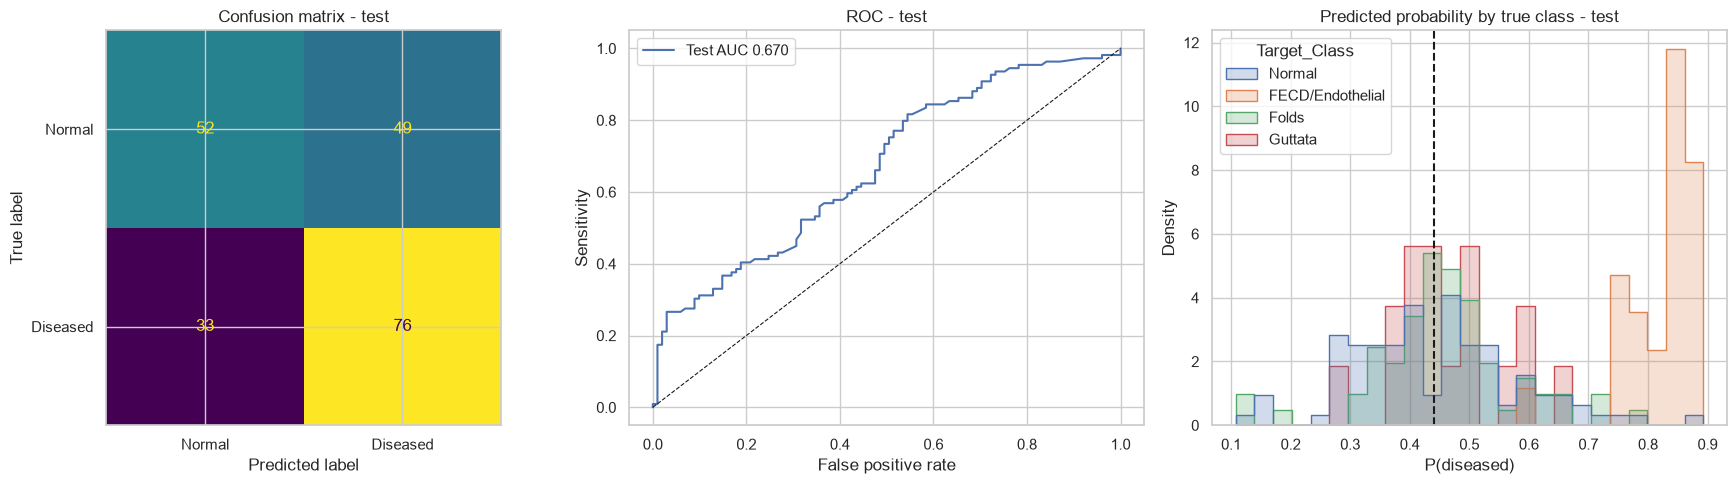

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, test_pred),
                       display_labels=["Normal", "Diseased"]).plot(ax=axes[0], colorbar=False)
axes[0].set_title("Confusion matrix - test")

fpr, tpr, _ = roc_curve(y_test, test_proba)
axes[1].plot(fpr, tpr, label=f"Test AUC {test_metrics['ROC_AUC']:.3f}")
axes[1].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[1].set(xlabel="False positive rate", ylabel="Sensitivity", title="ROC - test"); axes[1].legend()

sns.histplot(x=test_proba, hue=test["Target_Class"], bins=25, element="step",
             stat="density", common_norm=False, ax=axes[2])
axes[2].axvline(THRESHOLD, color="k", ls="--")
axes[2].set(xlabel="P(diseased)", title="Predicted probability by true class - test")
plt.tight_layout(); plt.show()

In [9]:
test_det = test.assign(Pred=test_pred).groupby("Target_Class").agg(
    n=("Pred", "size"), Predicted_Diseased=("Pred", "sum"), Rate=("Pred", "mean")).round(3)
print("Detection by true class - test (for Normal, Rate = false-positive rate)")
test_det

Detection by true class - test (for Normal, Rate = false-positive rate)


,n,Predicted_Diseased,Rate
Target_Class,,,
FECD/Endothelial,27,27,1.000
Folds,65,39,0.600
Guttata,17,10,0.588
Normal,101,49,0.485


,Importance,Std
ECD_CD_cells_per_mm2,0.1153,0.0306
Donor_Age,0.0123,0.0150
CV,0.0092,0.0175
ECD_Deficit,0.0009,0.0008
SD,-0.0004,0.0100
HEX_percent,-0.0085,0.0069


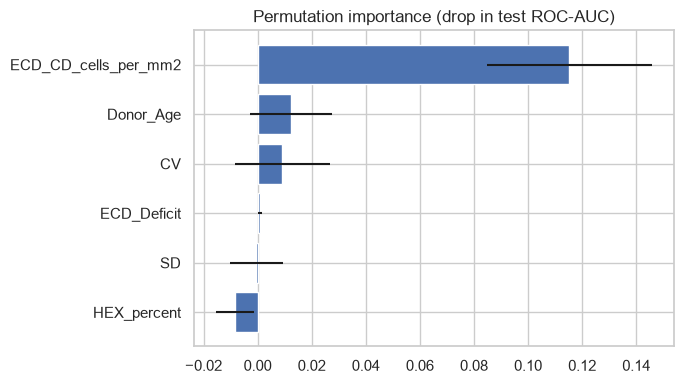

In [10]:
pi = permutation_importance(final_model, X_test, y_test, scoring="roc_auc",
                            n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.DataFrame({"Importance": pi.importances_mean, "Std": pi.importances_std},
                   index=FEATURES).sort_values("Importance", ascending=False)
display(imp.round(4))

plt.figure(figsize=(7, 4))
plt.barh(imp.index[::-1], imp["Importance"][::-1], xerr=imp["Std"][::-1])
plt.title("Permutation importance (drop in test ROC-AUC)"); plt.tight_layout(); plt.show()

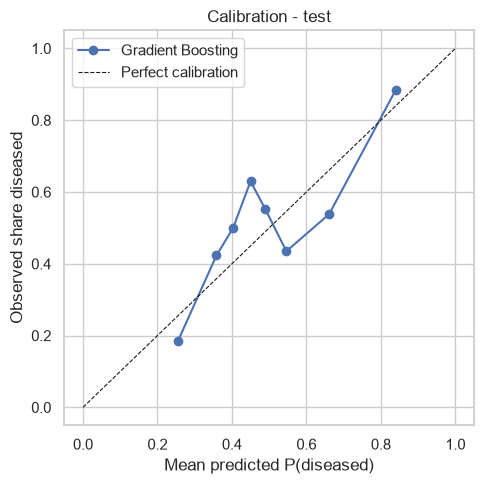

In [11]:
frac_pos, mean_pred = calibration_curve(y_test, test_proba, n_bins=8, strategy="quantile")
plt.figure(figsize=(5, 5))
plt.plot(mean_pred, frac_pos, marker="o", label=BEST_NAME)
plt.plot([0, 1], [0, 1], "k--", lw=0.8, label="Perfect calibration")
plt.xlabel("Mean predicted P(diseased)"); plt.ylabel("Observed share diseased")
plt.title("Calibration - test"); plt.legend(); plt.tight_layout(); plt.show()

In [12]:
joblib.dump(final_model, os.path.join(OUT_DIR, "model1_disease_present.joblib"))
with open(os.path.join(OUT_DIR, "model1_disease_present.json"), "w") as f:
    json.dump({"model": BEST_NAME,
               "params": {k: str(v) for k, v in cv_results.loc[BEST_NAME, "Best_params"].items()},
               "features": FEATURES, "threshold": THRESHOLD,
               "cv_train": cv_results.loc[BEST_NAME].drop("Best_params").astype(float).round(4).to_dict(),
               "test": {k: round(float(v), 4) for k, v in test_metrics.items()}}, f, indent=2)
test.assign(P_Diseased=test_proba, Pred_Diseased=test_pred)[
    ["Tissue_ID", "Target_Class", "Disease_Present", "P_Diseased", "Pred_Diseased"]
].to_csv(os.path.join(OUT_DIR, "model1_test_predictions.csv"), index=False)
print("Saved model1_disease_present.joblib, model1_disease_present.json, model1_test_predictions.csv")

Saved model1_disease_present.joblib, model1_disease_present.json, model1_test_predictions.csv
